# 01 — NISAR Product Setup, Discovery & First Map

Start by pointing this notebook at one NISAR HDF5 product. From there we walk its internal structure and put the acquisition on a map before doing anything else — knowing where the data actually sits on Earth matters for everything that follows.

In [1]:

import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

print("Repository root:", ROOT)
print("nisar_utils exists:", (ROOT / "nisar_utils").exists())


Repository root: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training
nisar_utils exists: True


In [2]:
from pathlib import Path
from nisar_utils.bootstrap import setup_workshop
WORKSHOP_ROOT=setup_workshop()
from nisar_utils.config import save_session
from nisar_utils.product import identify_nisar_product
print("Enter the complete path to one NISAR HDF5 product.")
NISAR_FILE=Path(input("NISAR file path: ").strip().strip('"'))
if not NISAR_FILE.exists(): raise FileNotFoundError(f"File not found: {NISAR_FILE}")
profile=identify_nisar_product(NISAR_FILE,verify_hdf5=True)
save_session({"nisar_file":str(NISAR_FILE.resolve())})
print("Product:",profile.product_type,profile.product_level,profile.sar_family,profile.band)
print("Frequencies:",profile.frequencies)
print("Polarization:",profile.polarization_code,profile.polarization_channels)
print("EPSG:",profile.epsg)


Enter the complete path to one NISAR HDF5 product.


NISAR file path:  "C:\Users\D. Sri Shashank\Desktop\Geosense\NISAR_Data\NISAR_S2_UR_GCOV_030_098_A_014_3700_DHNA_A_20260912T233809_20260912T233846_P00500_N_F_I_001.h5"


Product: GCOV L2 SSAR S
Frequencies: ['frequencyA']
Polarization: DHNA ['HH', 'HV']
EPSG: 32645


## 01A — Locate the NISAR acquisition

The footprint below comes straight from the product's own geocoded grid and CRS — none of it is hard-coded ahead of time.

In [3]:
from nisar_utils.gcov import open_gcov,get_grid_coordinates
from nisar_utils.mapping import scene_extent_wgs84,plot_scene_overview,folium_scene_map
freq=profile.frequencies[0]
grid=f"{profile.gcov_root}/grids/{freq}"
with open_gcov(NISAR_FILE) as f: x,y=get_grid_coordinates(f,grid)
scene_bounds,scene_polygon=scene_extent_wgs84(x,y,profile.epsg)
print("WGS84 extent:",scene_bounds)


WGS84 extent: {'lon_min': 84.45273883181846, 'lat_min': 23.242677714908236, 'lon_max': 87.87631906483452, 'lat_max': 26.250801230950316}


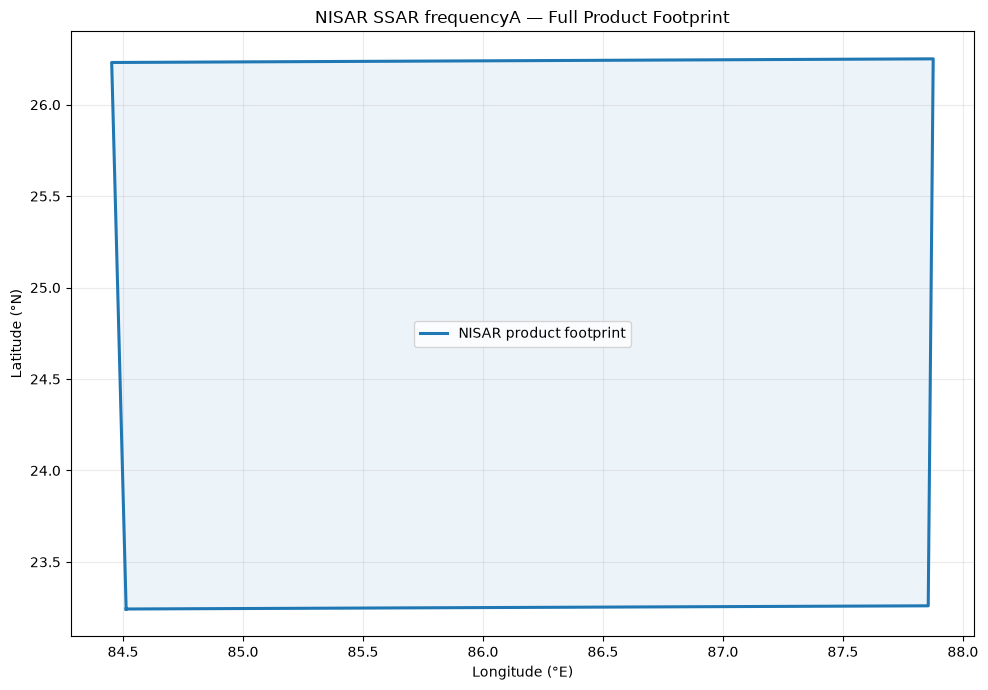

In [4]:
fig,ax=plot_scene_overview(x,y,profile.epsg,title=f"NISAR {profile.sar_family} {freq} — Full Product Footprint")


In [5]:
product_map=folium_scene_map(x,y,profile.epsg,title=f"NISAR {profile.sar_family} {freq} — Interactive Product Map")
product_map


### Participant checkpoint
Before moving on, jot down: where is this scene, what's its footprint, and which CRS is it in? You'll want that CRS number later.

In [6]:
print("Module 01 STATUS: PASS — product registered and geographic footprint established")

Module 01 STATUS: PASS — product registered and geographic footprint established


In [7]:
import os
import sys
from pathlib import Path

print("CURRENT DIRECTORY:")
print(Path.cwd())

print("\nPYTHON LOCATION:")
print(sys.executable)

print("\nCURRENT DIRECTORY CONTENTS:")
print(list(Path.cwd().iterdir())[:15])

print("\nCAN PYTHON SEE NISAR_UTILS?")
print(Path("nisar_utils").exists())
print(Path("../nisar_utils").exists())

CURRENT DIRECTORY:
C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\notebooks

PYTHON LOCATION:
C:\Users\D. Sri Shashank\miniconda3\envs\nisar-training\python.exe

CURRENT DIRECTORY CONTENTS:
[WindowsPath('C:/Users/D. Sri Shashank/Desktop/Geosense/nisar-polarimetric-training/notebooks/.ipynb_checkpoints'), WindowsPath('C:/Users/D. Sri Shashank/Desktop/Geosense/nisar-polarimetric-training/notebooks/01_Setup_and_Product_Selection.ipynb'), WindowsPath('C:/Users/D. Sri Shashank/Desktop/Geosense/nisar-polarimetric-training/notebooks/01_Setup_and_Product_Selection.ipynb.bak'), WindowsPath('C:/Users/D. Sri Shashank/Desktop/Geosense/nisar-polarimetric-training/notebooks/02_Session_Check_and_Product_Orientation.ipynb'), WindowsPath('C:/Users/D. Sri Shashank/Desktop/Geosense/nisar-polarimetric-training/notebooks/02_Session_Check_and_Product_Orientation.ipynb.bak'), WindowsPath('C:/Users/D. Sri Shashank/Desktop/Geosense/nisar-polarimetric-training/notebooks/03_NISAR_L1_Produc

In [8]:
from pathlib import Path

DATA_FOLDER = Path(r"C:\Users\D. Sri Shashank\Desktop\Geosense\NISAR_Data")

files = list(DATA_FOLDER.glob("*.h5"))

print("HDF5 files found:", len(files))

for f in files:
    print("Filename:", f.name)
    print("Size:", round(f.stat().st_size / (1024**2), 2), "MB")

HDF5 files found: 4
Filename: NISAR_L2_PR_GCOV_030_098_A_014_4005_DHDH_A_20260912T233810_20260912T233845_P05023_N_F_J_001.h5
Size: 6668.0 MB
Filename: NISAR_L2_PR_GCOV_034_098_A_014_4005_DHDH_A_20261030T233811_20261030T233845_P05036_N_F_J_001.h5
Size: 6484.0 MB
Filename: NISAR_S2_UR_GCOV_030_098_A_014_3700_DHNA_A_20260912T233809_20260912T233846_P00500_N_F_I_001.h5
Size: 12035.23 MB
Filename: NISAR_S2_UR_GCOV_034_098_A_014_3700_DHNA_A_20261030T233811_20261030T233847_P00500_M_F_I_001.h5
Size: 12047.26 MB
